# Milestone 4 | Weather Regression

## Objective

This notebook extends Model 1 by adding six weather
variables: temperature, humidity, wind speed,
precipitation, atmospheric pressure, and visibility.

The objective is to examine how weather conditions
are associated with arrival delays after accounting
for flight characteristics.

Both models are compared using the same complete-case
sample to evaluate the additional explanatory power
of weather variables.

In [2]:
# Import Libraries

import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

In [3]:
# Load the dataset

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "milestone4_statistical_analysis":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "analysis_ready_flights.csv"

assert DATA_PATH.exists(), f"File not found: {DATA_PATH}"

flights = pd.read_csv(DATA_PATH)

print("Data file found:", DATA_PATH.exists())

Data file found: True


In [3]:
# Create Dataset for Model 2

model2_cols = [
    "arr_delay",
    "season",
    "carrier",
    "scheduled_hour",
    "distance",
    "origin",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "pressure",
    "visib"

]


In [4]:
# Remove rows with missing values in the selected columns
missing_values = flights[model2_cols].isna().sum()

missing_percent = (
    flights[model2_cols].isna().mean() * 100
).round(2)

print("\nMissing Counts:")
print(missing_values)

print("\nMissing Percentages:")
print(missing_percent)

model2_data = flights[model2_cols].dropna()

# Check sample size after dropping missing values
print(f"\nSample size after dropping missing values: {len(model2_data):,}"
      f"of {len(flights):,} flights")

print(f"Excluded flights: "
      f"{len(flights) - len(model2_data):,} flights")


Missing Counts:
arr_delay             0
season                0
carrier               0
scheduled_hour        0
distance              0
origin                0
temp               1544
humid              1544
wind_speed         1605
precip             1527
pressure          36142
visib              1527
dtype: int64

Missing Percentages:
arr_delay          0.00
season             0.00
carrier            0.00
scheduled_hour     0.00
distance           0.00
origin             0.00
temp               0.47
humid              0.47
wind_speed         0.49
precip             0.47
pressure          11.04
visib              0.47
dtype: float64

Sample size after dropping missing values: 291,140of 327,346 flights
Excluded flights: 36,206 flights


## Missing Value Treatment

After removing observations with missing values in
the selected variables, 291,140 of 327,346 flights
remained.

A total of 36,206 flights (11.06%) were excluded.
Atmospheric pressure had the highest missing rate
(11.04%), while the other weather variables had
missing rates below 0.5%.

We use complete-case analysis to ensure that both
regression models are compared using the same flights.
However, excluding incomplete observations may
introduce selection bias if missingness is related
to flight delays or weather conditions.

This limitation will be further examined in the
model validation stage.

In [5]:
# Create Model 1 Comparison dataset from Model 2 sample

model1_comparison_data = model2_data[
    ['arr_delay', 'season', 'carrier', 'scheduled_hour', 'distance', 'origin']
].copy() 

In [6]:
# Check sample size after removing missing values
print(f"Sample size for Model 2: {len(model2_data)}")
print(f"Flights excluded:", len(flights) - len(model2_data))

Sample size for Model 2: 291140
Flights excluded: 36206


In [7]:
# Check for missing values in the selected columns

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
arr_delay             0
season                0
carrier               0
scheduled_hour        0
distance              0
origin                0
temp               1544
humid              1544
wind_speed         1605
precip             1527
pressure          36142
visib              1527
dtype: int64


In [8]:
# Summary statistics for weather variables

weather_summary = model2_data[['temp', 'humid', 'wind_speed', 'precip', 'pressure', 'visib']].describe()

print("Summary statistics for weather variables:")
print(weather_summary)

Summary statistics for weather variables:
                temp          humid     wind_speed         precip  \
count  291140.000000  291140.000000  291140.000000  291140.000000   
mean       57.077140      56.148008      10.959332       0.001348   
std        18.079445      18.034573       5.484414       0.012589   
min        10.940000      12.740000       0.000000       0.000000   
25%        42.080000      42.320000       6.904680       0.000000   
50%        57.020000      54.350000      10.357020       0.000000   
75%        73.040000      69.320000      13.809360       0.000000   
max       100.040000     100.000000      39.126520       0.530000   

            pressure          visib  
count  291140.000000  291140.000000  
mean     1017.900041       9.587284  
std         7.419816       1.455421  
min       983.800000       0.000000  
25%      1012.900000      10.000000  
50%      1017.600000      10.000000  
75%      1022.900000      10.000000  
max      1042.100000      10.000

,flight_count,avg_delay
rain_flag,,
0,304877,5.051991
1,20942,33.535813


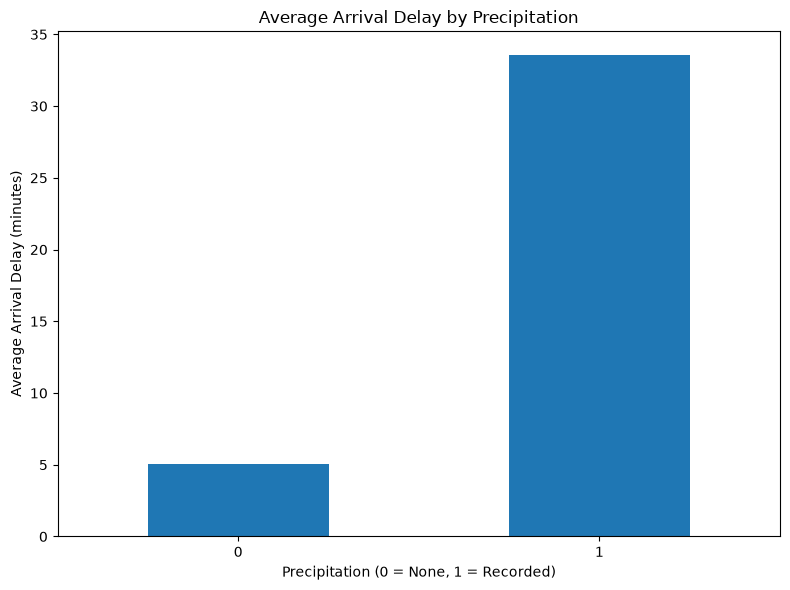

In [9]:
# Use flights with recorded precipitation values
rain_data = flights.dropna(subset=["precip"]).copy()

# Create a precipitation flag
rain_data["rain_flag"] = (
    rain_data["precip"] > 0
).astype(int)

# Calculate average arrival delay by precipitation
rain_summary = rain_data.groupby("rain_flag").agg(
    flight_count=("arr_delay", "count"),
    avg_delay=("arr_delay", "mean")
)

display(rain_summary)

# Visualize average arrival delay
rain_summary["avg_delay"].plot(
    kind="bar",
    figsize=(8, 6),
    legend=False
)

plt.title("Average Arrival Delay by Precipitation")
plt.xlabel("Precipitation (0 = None, 1 = Recorded)")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Flights with recorded precipitation are compared
with flights without precipitation.

Observations with missing precipitation values
are excluded from this comparison.

This is a descriptive comparison and does not
control for other flight or weather characteristics.

,flight_count,avg_delay
visibility_group,,
Very Low,4942,34.377378
Low,10359,25.958008
Moderate,6650,18.535639
High,303868,5.530326


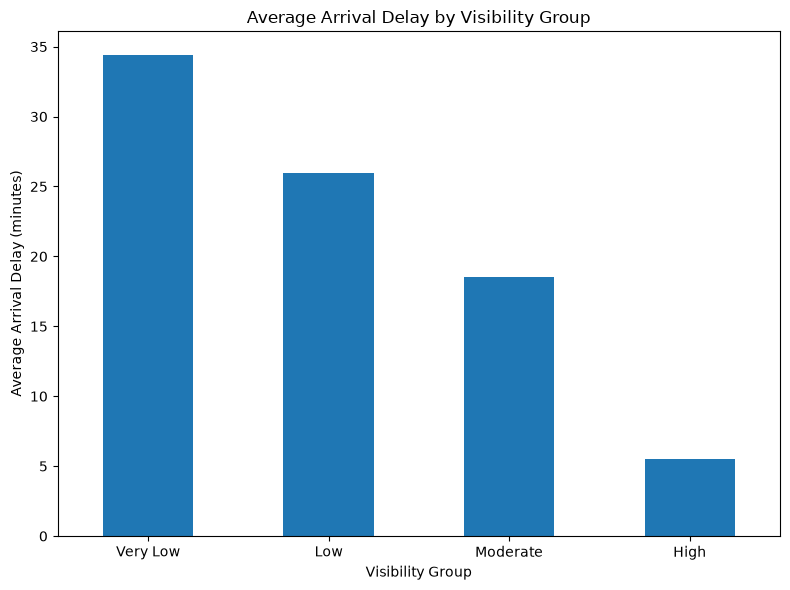

In [10]:
# Use flights with recorded visibility values
visibility_data = flights.dropna(
    subset=["visib"]
).copy()

# Create visibility groups
visibility_data["visibility_group"] = pd.cut(
    visibility_data["visib"],
    bins=[-1, 1, 3, 5, 10],
    labels=["Very Low", "Low", "Moderate", "High"]
)

# Calculate summary statistics
visibility_summary = visibility_data.groupby(
    "visibility_group", observed=True
).agg(
    flight_count=("arr_delay", "count"),
    avg_delay=("arr_delay", "mean")
)

display(visibility_summary)

# Visualize average arrival delay
visibility_summary["avg_delay"].plot(
    kind="bar",
    legend=False,
    figsize=(8, 6)
)

plt.title("Average Arrival Delay by Visibility Group")
plt.xlabel("Visibility Group")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

This comparison examines how average arrival delays
vary across different visibility conditions.

Missing visibility values are excluded. The results
describe an association and do not establish a
causal relationship.

Correlations with Arrival Delay:
arr_delay     1.000000
humid         0.141397
precip        0.111281
wind_speed    0.064069
temp          0.033026
visib        -0.135536
Name: arr_delay, dtype: float64


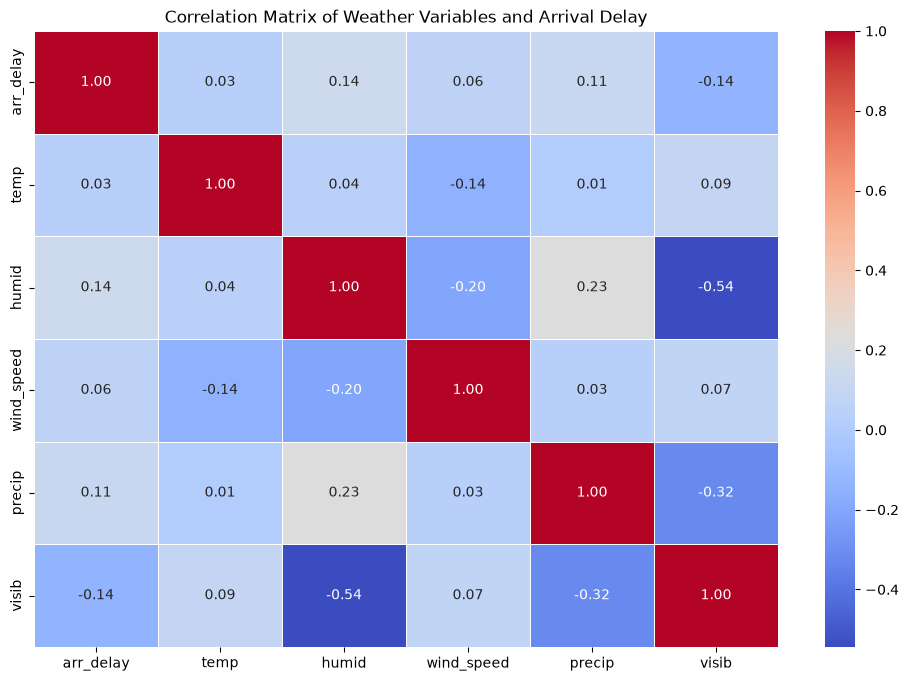

In [11]:
# Select weather-related variables for correlation analysis

weather_vars = [
    "arr_delay",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "visib"
]

# Calculate correlation matrix

correlation_matrix = flights[weather_vars].corr()

# Display correlations with arrival delay
print("Correlations with Arrival Delay:")
print(correlation_matrix['arr_delay'].sort_values(ascending=False))

# Create a heatmap to visualize the correlation matrix

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Correlation Matrix of Weather Variables and Arrival Delay")
plt.show()  

Most individual correlations are relatively weak, suggesting weather conditions may be more informative when collectively evaluated through a regression model as opposed to through pairwise relationships alone. 

No missing values remain win the variables used for model 2 after removing incomplete observations.

In [12]:
# Create reference categories for the 'season' variable

model2_data['season'] = pd.Categorical(
model2_data['season'], 
categories=['Winter', 'Spring', 'Summer', 'Fall']
)

# create Reference categories for the airline variable

model2_data['carrier'] = pd.Categorical(
    model2_data['carrier'], 
    categories=[
        "AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA", "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"
    ]   
)

# Create reference categories for the airport variable

model2_data['origin'] = pd.Categorical(
    model2_data['origin'], 
    categories=["JFK", "LGA", "EWR"]
)


In [13]:
# Create Dummy Variables for Categorical Variables

model2_data = pd.get_dummies(model2_data, columns=['season', 'carrier', 'origin'], drop_first=True, dtype=int)

# Check resulting dataset

print("Shape of the dataset after creating dummy variables:", model2_data.shape)
print(model2_data.head())

Shape of the dataset after creating dummy variables: (291140, 29)
   arr_delay  scheduled_hour  distance   temp  humid  wind_speed  precip  \
0       11.0               5      1400  39.02  64.43    12.65858     0.0   
1       20.0               5      1416  39.92  54.81    14.96014     0.0   
2       33.0               5      1089  39.02  61.63    14.96014     0.0   
3      -18.0               5      1576  39.02  61.63    14.96014     0.0   
4      -25.0               6       762  39.92  54.81    16.11092     0.0   

   pressure  visib  season_Spring  ...  carrier_MQ  carrier_OO  carrier_UA  \
0    1011.9   10.0              0  ...           0           0           1   
1    1011.4   10.0              0  ...           0           0           1   
2    1012.1   10.0              0  ...           0           0           0   
3    1012.1   10.0              0  ...           0           0           0   
4    1011.7   10.0              0  ...           0           0           0   

   carri

Dummy variables created for season, airline, and airport with the first category in each group serving as the reference category.

In [14]:
# create the independent variables (X) and dependent variable (y)

y_model2 = model2_data['arr_delay']
X_model2 = model2_data.drop('arr_delay', axis=1)

# create intercept for the regression model

X_model2=sm.add_constant(X_model2)

# Fit the regression model

model2_fit = sm.OLS(y_model2, X_model2).fit()

# Results

print(model2_fit.summary())


                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     899.9
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:16:07   Log-Likelihood:            -1.4889e+06
No. Observations:              291140   AIC:                         2.978e+06
Df Residuals:                  291111   BIC:                         2.978e+06
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            399.6132     11.682     34.

Model 2 adds weather variables including temperature, humidity, wind speed, precipitation, atmospheric pressure, and visibility. 

In [15]:
# Calculate Variance Inflation Factor (VIF) for each independent variable

vif_data = pd.DataFrame()
vif_data['Variable'] = X_model2.columns
vif_data['VIF'] = [variance_inflation_factor(X_model2.values, i) for i in range(X_model2.shape[1])]
print(vif_data.sort_values('VIF', ascending=False).reset_index(drop=True))


          Variable       VIF
0    season_Summer  4.470108
1             temp  3.075085
2       carrier_EV  2.958365
3       carrier_UA  2.880848
4       origin_EWR  2.688712
5       carrier_B6  2.482982
6      season_Fall  2.476548
7       carrier_DL  2.135081
8    season_Spring  2.043204
9       origin_LGA  1.994130
10      carrier_MQ  1.780191
11        distance  1.698729
12      carrier_9E  1.681012
13      carrier_US  1.632400
14           humid  1.555715
15           visib  1.479729
16      carrier_WN  1.395725
17      wind_speed  1.288700
18        pressure  1.250963
19      carrier_VX  1.208053
20          precip  1.160296
21      carrier_FL  1.114317
22  scheduled_hour  1.097478
23      carrier_HA  1.048606
24      carrier_AS  1.042619
25      carrier_F9  1.024614
26      carrier_YV  1.023336
27      carrier_OO  1.001382
28           const  1.000000


### Multicollinearity

Excluding the intercept, all predictor VIF values
were below 5.

The highest VIF was approximately 4.47 for Summer,
followed by temperature at 3.08.

These results suggest that multicollinearity is
not a major concern based on the commonly used
VIF threshold of 5. Therefore, all predictors
were retained.

In [16]:
# Calculate heteroskedasticity-robust standard errors

model2_robust = model2_fit.get_robustcov_results(cov_type='HC3')

# Results

print(model2_robust.summary())

                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     681.7
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:20:01   Log-Likelihood:            -1.4889e+06
No. Observations:              291140   AIC:                         2.978e+06
Df Residuals:                  291111   BIC:                         2.978e+06
Df Model:                          28                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            399.6132     11.876     33.

In [17]:
# test for heteroskedasticity using Breusch-Pagan test

# Use the design matrix, which already includes an intercept
bp_exog = X_model2

bp_test = het_breuschpagan(model2_fit.resid, bp_exog)

print("LM Statistic:", bp_test[0])
print("p-value:", bp_test[1])

LM Statistic: 2859.5151829082643
p-value: 0.0


In [18]:
print(X_model2.columns[:5])

Index(['const', 'scheduled_hour', 'distance', 'temp', 'humid'], dtype='str')


### Heteroskedasticity

The Breusch-Pagan test indicated statistically
significant evidence of heteroskedasticity
(p < 0.001).

HC3 robust standard errors are used to account
for nonconstant residual variance when conducting
statistical inference.

This adjusts standard errors, confidence intervals,
and p-values without changing the estimated
regression coefficients or R-squared.

In [19]:
# Display weather coefficients only

weather_coeffs = model2_fit.params[['temp', 'humid', 'wind_speed', 'precip', 'pressure', 'visib']]
print("Weather Coefficients:")
print(weather_coeffs.sort_values(key=abs, ascending=False))


Weather Coefficients:
precip        70.584274
visib         -1.200840
pressure      -0.415930
wind_speed     0.388695
humid          0.229213
temp          -0.060654
dtype: float64


### Interpretation of Weather Coefficients

Holding all other predictors constant:

- A 10°F increase in temperature is associated
  with approximately 0.61 fewer minutes of delay.
- A 10-percentage-point increase in humidity is
  associated with 2.29 additional minutes of delay.
- A 10 mph increase in wind speed is associated
  with 3.89 additional minutes of delay.
- A 0.1-inch increase in precipitation is associated
  with 7.06 additional minutes of delay.
- A 10 hPa increase in atmospheric pressure is
  associated with 4.16 fewer minutes of delay.
- A one-mile increase in visibility is associated
  with 1.20 fewer minutes of delay.

All six weather variables were statistically
significant at the 0.05 level using HC3 robust
standard errors.

Because the weather variables are measured in
different units, their raw coefficients should
not be directly compared to determine which
variable has the strongest association.

These estimates represent associations rather
than causal effects.

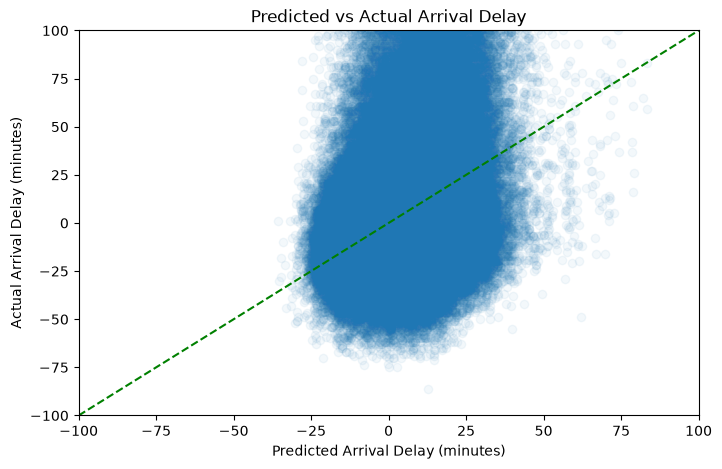

In [20]:
# Compare predicted and actual arrival delays

predicted = model2_fit.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(
    predicted,
    y_model2,
    alpha=0.05
)

plt.xlabel("Predicted Arrival Delay (minutes)")
plt.ylabel("Actual Arrival Delay (minutes)")
plt.title("Predicted vs Actual Arrival Delay")
plt.xlim(-100, 100)
plt.ylim(-100, 100)
plt.axline((0, 0), slope=1, color='Green', linestyle='--')

plt.show()

The model captures general delay patterns, however, substantial variation remains unexplained. 

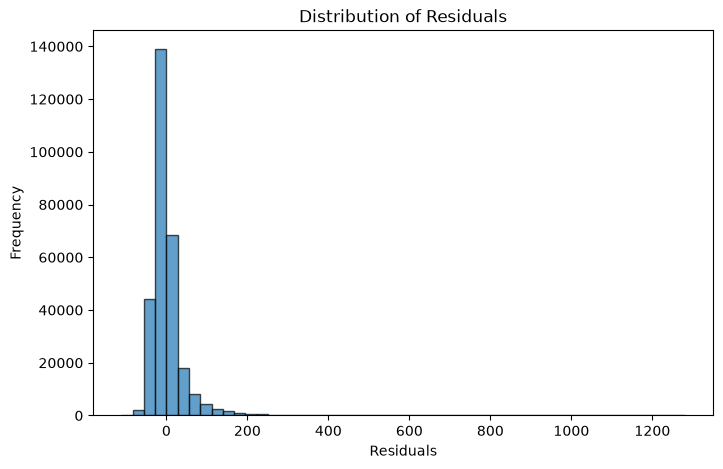

In [21]:
# Distribution of residuals

plt.figure(figsize=(8,5))

plt.hist(
    model2_fit.resid,
    bins=50,
    edgecolor='k',
    alpha=0.7
)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

The distribution of residuals is right skewed which sugguests unusually large delays are still difficult to explain with the variables included in the model.

In [22]:
# Set reference categories

model1_comparison_data["season"] = pd.Categorical(
    model1_comparison_data["season"],   
    categories=["Winter", "Spring", "Summer", "Fall"]   
)

model1_comparison_data["carrier"] = pd.Categorical(
    model1_comparison_data["carrier"],  
    categories = [
            "AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA", "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"
            ]   
)

model1_comparison_data["origin"] = pd.Categorical(
    model1_comparison_data["origin"],   
    categories=["JFK", "LGA", "EWR"]
)



In [23]:
# create dummy variables

model1_comparison_data = pd.get_dummies(model1_comparison_data, columns=['season', 'carrier', 'origin'], drop_first=True, dtype=int)

In [24]:
# Run Model 1 on the same sample as Model 2

y_model1 = model1_comparison_data['arr_delay']
X_model1 = model1_comparison_data.drop(
    columns=['arr_delay']
)
x_model1 = sm.add_constant(X_model1)

model1_comparison = sm.OLS(y_model1, x_model1).fit()



In [25]:
comparison = pd.DataFrame({
    "Metric": ["R-squared", "Adj. R-squared", "AIC", "BIC"],
    "Model 1": [
        round(model1_comparison.rsquared, 4),
        round(model1_comparison.rsquared_adj, 4),
        round(model1_comparison.aic, 4),
        round(model1_comparison.bic, 4)
    ],
    "Model 2": [
        round(model2_fit.rsquared, 4),
        round(model2_fit.rsquared_adj, 4),
        round(model2_fit.aic, 4),
        round(model2_fit.bic, 4)
    ]
})

print(comparison)

           Metric       Model 1       Model 2
0       R-squared  5.400000e-02  7.970000e-02
1  Adj. R-squared  5.390000e-02  7.960000e-02
2             AIC  2.985835e+06  2.977827e+06
3             BIC  2.986079e+06  2.978134e+06


## Model Comparison and Conclusion

Both models were estimated using the same sample
of 291,140 flights.

Model 1 explained approximately 5.40% of the
variation in arrival delays, while Model 2
explained approximately 7.97%.

Adding weather variables increased R-squared by
2.57 percentage points. Model 2 also achieved
a higher adjusted R-squared and lower AIC and BIC
values.

These results suggest that weather conditions
provide additional explanatory power beyond
flight characteristics alone.

However, approximately 92% of the variation in
arrival delays remains unexplained by Model 2.
Other operational factors and unexpected events
may account for some of this variation.

Model 2 provides a better in-sample fit, but
further validation is needed to evaluate its
predictive performance and sensitivity to missing
values and extreme delays.

In [26]:
print(model2_data.shape)

(291140, 29)
